In [27]:
import numpy as np
import os
import re
import seaborn as sns
import pandas as pd # type: ignore
import matplotlib.pyplot as plt # type: ignore
import funciones as f
from sklearn.impute import SimpleImputer

In [28]:
folder_path = "./datasetsWC26"


match_file1 = os.path.join(folder_path, "matches_mundial2026.csv")
match_file2 = os.path.join(folder_path, "matches_mundial202.csv")
stages_file = os.path.join(folder_path, "tournament_stages.csv")
venues_file = os.path.join(folder_path, "worldcup_venues.csv")
teams_file = os.path.join(folder_path, "2026nationalteams.csv")
refs_file =  os.path.join(folder_path, "index_referees.csv")
players_file = os.path.join(folder_path, "2026squads_and_players.csv")
stats_file = os.path.join(folder_path, "2026player_stats.csv")
events_file = os.path.join(folder_path, "2026match_register.csv")

#Player Stats
player_stats = pd.read_csv(
    filepath_or_buffer = stats_file,
    sep = f.separator(stats_file)
)

#Match Events
events = pd.read_csv(
    filepath_or_buffer = events_file,
    sep = f.separator(events_file)
).drop_duplicates()

#Referees
referees = pd.read_csv(
    filepath_or_buffer = refs_file,
    sep = f.separator(refs_file)
).drop_duplicates().drop(columns = ["referee_id.1"])

#National Teams
national_teams = pd.read_csv(
    filepath_or_buffer = teams_file, 
    sep = f.separator(teams_file)
).drop_duplicates()

#Estadios Mundialistas
wc_venues = pd.read_csv(
    filepath_or_buffer = venues_file,
    sep = f.separator(venues_file)
).drop_duplicates()

#Rondas del Mundial
wc_stages = pd.read_csv(
    filepath_or_buffer = stages_file,
    sep = f.separator(stages_file)
).drop_duplicates()

#Partidos del Mundial 2026
matches_2026 = pd.read_csv(
    filepath_or_buffer = match_file1,
    sep = f.separator(match_file1)
).drop_duplicates()



#Usamos numpy para optimizar la evaluación del condicional
matches_2026["prorroga"] = np.where(matches_2026["result_type"] == "Regular", "NO", "SI")

drop_match_cols = ['match_id', 'kickoff_time_utc', 'status', 'result_type', 'home_xg', 'away_xg', 'player_of_the_match_id', 'capacidad_estadio_pct', 'clima']

matches_2026 = matches_2026.drop(columns=drop_match_cols)
matches_2026.fillna(0, inplace=True)

#Hacemos merge para tener el nombre de la etapa
matches_2026 = pd.merge(
    matches_2026, wc_stages[["stage_id", "stage_name"]],
    on = "stage_id", #igual en ambos dfs
    how = "left"
)
matches_2026 = matches_2026.drop(columns = ["stage_id"])

#Repetimos el proceso para el nombre y ciudad del estadio
matches_2026 = pd.merge(
    matches_2026, wc_venues[["venue_id", "stadium_name", "city", "country"]],
    on = "venue_id",
    how= "left"
)
matches_2026 = matches_2026.drop(columns = ["venue_id"])

#Ahora hagámoslo para los países enfrentados
teams_cols = ["home_team_id", "away_team_id"]

for col in teams_cols:
    matches_2026 = pd.merge(
        matches_2026, national_teams[["team_id", "team_name"]],
        left_on = col,
        right_on = "team_id",
        how = "left",
    ).drop(columns = [col, "team_id"])


#Por último, para los árbitros

matches_2026 = pd.merge(
    matches_2026, referees[["referee_id", "name"]],
    on = "referee_id",
    how = "left"
).drop(columns=["referee_id"])

#Ya que tenemos todas las columnas, buscamos renombrarlas

traduccion_columnas = {
    'date': 'fecha_partido',
    'home_score': 'marcador_local',
    'away_score': 'marcador_visitante',
    'home_penalty_score': 'penalty_local',
    'away_penalty_score': 'penalty_visitante',
    'prorroga': 'prorroga',
    'stage_name': 'ronda',
    'stadium_name': 'estadio',
    'city': 'ciudad_partido',
    'country': 'pais_partido',
    'team_name_x': 'seleccion_local',
    'team_name_y': 'seleccion_visitante',
    'name': 'arbitro_partido'
}

matches_2026.rename(columns=traduccion_columnas, inplace=True)

In [29]:
date_regex = [
    # Se reordena (Días: 10-31 primero, luego 0-9) y (Meses: 10-12 primero, luego 0-9)
    r"(?:[1-2]\d|3[0-1]|0?[1-9])/(?:1[0-2]|0?[1-9])/2026",
    r"(?:[1-2]\d|3[0-1]|0?[1-9])\s[A-Z][a-z]+\s2026",
    r"[A-Z][a-z]+\s(?:[1-2]\d|3[0-1]|0?[1-9]),\s2026",
    r"(?:[1-2]\d|3[0-1]|0?[1-9])-[a-z]{3}-26",
    r"2026-(?:1[0-2]|0?[1-9])-(?:[1-2]\d|3[0-1]|0?[1-9])",
    r"(?:[1-2]\d|3[0-1]|0?[1-9])\.(?:1[0-2]|0?[1-9])\.2026",
    r"[A-Z][a-z]{2}\s(?:[1-2]\d|3[0-1]|0?[1-9])\s2026",
    r"2026(?:1[0-2]|0?[1-9])(?:[1-2]\d|3[0-1]|0?[1-9])", 
    r"(?:[1-2]\d|3[0-1]|0?[1-9]) de [a-z]+ de 2026",
    r"(?:1[0-2]|0?[1-9])-(?:[1-2]\d|3[0-1]|0?[1-9])-2026",
    r"(?:[1-2]\d|3[0-1]|0?[1-9])-[A-Z][a-z]{2}-2026",
    r"2026-(?:1[0-2]|0?[1-9])-(?:[1-2]\d|3[0-1]|0?[1-9])T\d{2}:\d{2}:\d{2}Z", 
    r"(?:1[0-2]|0?[1-9])/(?:[1-2]\d|3[0-1]|0?[1-9])/2026"
]

pattern = f"({"|".join(date_regex)})"

# Usamos regex aquí => usamos [0] porque devuelve un df con nombre de columna 0
fecha_texto = matches_2026["fecha_partido"].str.extract(pattern)[0]

traduccion_meses = {
    ' de enero de ': ' January ', ' de febrero de ': ' February ',
    ' de marzo de ': ' March ', ' de abril de ': ' April ',
    ' de mayo de ': ' May ', ' de junio de ': ' June ',
    ' de julio de ': ' July ', ' de agosto de ': ' August ',
    ' de septiembre de ': ' September ', ' de octubre de ': ' October ',
    ' de noviembre de ': ' November ', ' de diciembre de ': ' December '
}


fecha_texto = fecha_texto.replace(traduccion_meses, regex=True)

clean_dates = pd.to_datetime(
    arg = fecha_texto, 
    errors = "coerce", 
    dayfirst = True,
    format = "mixed"
)

matches_2026["fecha_partido"] = clean_dates.dt.strftime("%d/%m/%Y")

matches_2026["pais_partido"] = matches_2026["pais_partido"].str.upper()

matches_2026.head()

,fecha_partido,marcador_local,marcador_visitante,penalty_local,penalty_visitante,prorroga,ronda,estadio,ciudad_partido,pais_partido,seleccion_local,seleccion_visitante,arbitro_partido
0,11/06/2026,2,0,0.0,0.0,NO,Group Stage,Mexico City Stadium (Estadio Azteca),Mexico City,MEX,Mexico,South Africa,Wilton Sampaio
1,11/06/2026,2,1,0.0,0.0,NO,Group Stage,Guadalajara Stadium (Estadio Akron),Zapopan,MEX,South Korea,Czechia,Amin Omar
2,06/12/2026,1,1,0.0,0.0,NO,Group Stage,Toronto Stadium (BMO Field),Toronto,CAN,Canada,Bosnia and Herzegovina,Facundo Tello
3,12/06/2026,4,1,0.0,0.0,NO,Group Stage,Los Angeles Stadium (SoFi Stadium),Inglewood,USA,USA,Paraguay,Danny Makkelie
4,13/06/2026,1,1,0.0,0.0,NO,Group Stage,Boston Stadium (Gillette Stadium),Foxborough,USA,Qatar,Switzerland,Saíd Martínez


In [30]:
players = pd.read_csv(
    filepath_or_buffer = players_file, 
    sep = f.separator(players_file)
).drop_duplicates()

players.set_index("player_name", inplace = True)

players = pd.merge(
    players, national_teams[["team_id", "team_name"]],
    on = "team_id",
    how = "left",
).drop(columns = ["team_id"])

players["market_value_eur"] = players["market_value_eur"].replace(
    to_replace = 0.0,
    value = np.nan
)

mean_values = {
    country: players[players["team_name"] == country]["market_value_eur"].mean()
    for country in players["team_name"].unique()
}



players["market_value_eur"] = players["market_value_eur"].fillna(
    players["team_name"].map(mean_values)
    # Mappeamos los valores medios según el país del jugador
)



In [31]:
# Para las estadísticas, hay una columna sin nombrar.
# La de tiros a puerta está completamente vacía. => Se trata de un error, pues no puede ser que ni los delanteros tiren a puerta
# Los valores que faltan en los goles, asistencias y tarjetas tiene sentido que sean cero


player_stats = player_stats.drop(columns = ["Unnamed: 18"])



In [32]:
zero_column_stats = [
    "goals", 
    "assists", 
    "shots", 
    "shots_on_target",
    "yellow_cards",
    "red_cards", 
    "clean_sheets", 
    "saves", 
    "goals_conceded"
]

player_stats[zero_column_stats] = player_stats[zero_column_stats].fillna(0)

merge_columns = ["player_id","player_name","matches_played", "minutes_played", "goals", "assists", "shots", "yellow_cards", "red_cards", "saves", "goals_conceded", "average_rating"]

players = pd.merge(
    players, player_stats[merge_columns],
    on = "player_id",
    how = "left"
)
"""
Pendiente arreglar nombres jugadores, Z por E, ccasa por A...
"""

players["average_rating"].isna().sum()

np.int64(320)

In [33]:
#Ahora procedamos a imputar los valores que faltan de average_rating por regresión

from sklearn.linear_model import LinearRegression

model_gk = LinearRegression()
model_players = LinearRegression()


gk_cols_train = ["yellow_cards", "red_cards", "saves", "goals_conceded"]
players_cols_train = gk_cols_train[0:2] + ["goals", "assists", "shots"]

#Distinguimos el caso de los porteros
train_goalies = players[(players["average_rating"].notna()) & (players["position"] == "GK")]

X_train_gk = train_goalies[gk_cols_train]
y_train_gk = train_goalies["average_rating"]

model_gk.fit(X_train_gk, y_train_gk)

X_test_goalies = players[(players["average_rating"].isna()) & (players["position"] == "GK")][gk_cols_train]
y_pred_goalies = model_gk.predict(X_test_goalies)

y_pred_goalies = np.clip(y_pred_goalies, a_min = 0, a_max = 10)
players.loc[(players["average_rating"].isna()) & (players["position"] == "GK"), "average_rating"] = y_pred_goalies

#Ahora para el resto de jugadores
train_players = players[(players["average_rating"].notna()) & (players["position"] != "GK")]

X_train_players = train_players[players_cols_train]
y_train_players = train_players["average_rating"]

X_test_players = players[(players["average_rating"].isna()) & (players["position"] != "GK")][players_cols_train]

model_players.fit(X_train_players, y_train_players)
y_pred_players = model_players.predict(X_test_players)
y_pred_players = np.clip(y_pred_players, a_min = 0, a_max = 10)

players.loc[(players["average_rating"].isna()) & (players["position"] != "GK"), "average_rating"] = y_pred_players


traduccion_columnas_players = {
    'player_name': 'nombre_jugador',
    'team_name': 'seleccion_nacional',
    'club_team': 'club_jugador',
    'caps': 'partidos_seleccion',
    'position': 'posicion',
    'market_value_eur': 'valor_mercado',
    'matches_played': 'partidos_jugados',
    'minutes_played': 'minutos_jugados',
    'goals': 'goles',
    'assists': 'asistencias',
    'shots': 'tiros',
    'yellow_cards': 'tarjetas_amarillas',
    'red_cards': 'tarjetas_rojas',
    'saves': 'paradas',
    'goals_conceded': 'goles_concedidos',
    'average_rating': 'calificacion_media'
}

players.rename(
    columns = traduccion_columnas_players,
    inplace = True
)



letter_mistakes = {
    "Ž": "e",
    "ç": "A",
    "‡": "a",
    "œ": "u",
    "[?]": "s",
    "’": "i",
    "•": "ï",
    "-": "ñ"
}

#Necesitamos regex = True, porque sino buscará una palabra entera para las coincidencias
players["nombre_jugador"] = players["nombre_jugador"].replace(letter_mistakes, regex=True)

#Util tener el ID para el DF de eventos
players_with_id = players.copy()

players.set_index(keys = "nombre_jugador", inplace = True)

players = players.drop(columns = ["international_goals", "player_id"])


players.to_csv("players_updated.csv", sep = ",")

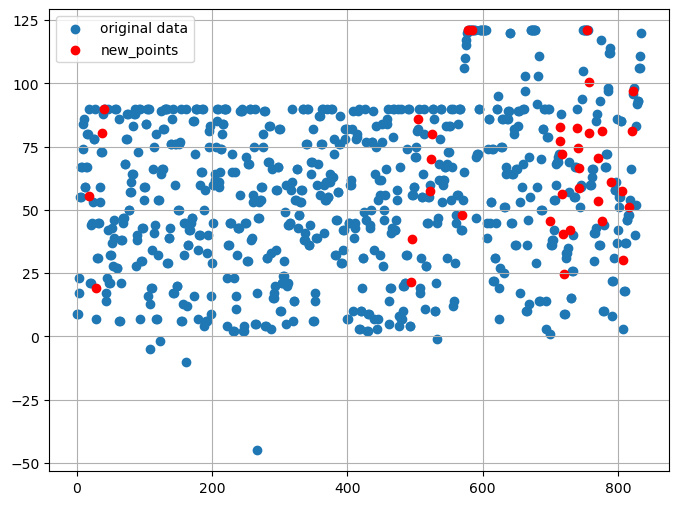

,index_partido,minuto_evento,tipo_evento,nombre_jugador,seleccion_evento
index_evento,,,,,
1,1.0,9.0,Goal,Julian Andres Quinones,Mexico
2,1.0,9.0,Assist,Erik Antonio Lira,Mexico
3,1.0,17.0,Yellow Card,Teboho Mokoena,South Africa
4,1.0,23.0,Yellow Card,Brian Gutierrez,Mexico
5,1.0,55.0,Red Card,Sphephelo S'miso Sithole,South Africa
...,...,...,...,...,...
830,104.0,93.0,Red Card,Enzo Jeremias Fernandez,Argentina
831,104.0,106.0,Goal,Ferran Torres,Spain
832,104.0,106.0,Assist,Nicholas Williams,Spain


In [34]:
# Hay varias filas que tienen todos los valores ausentes menos el event_id, esas las eliminaremos al no aportar absolutamente nada.
events = events[~(events.iloc[:, 1:].isna().all(axis = 1)) & ((events["minute"].isna()) | (events["minute"] < 130))]



events = pd.merge(
    events, players_with_id[["player_id", "nombre_jugador", "seleccion_nacional"]],
    how = "left", 
    on = "player_id"
).drop(columns = ["player_id", "team_id"])


events_translation = {
    'event_id': 'index_evento',
    'match_id': 'index_partido',
    'minute': 'minuto_evento',
    'event_type': 'tipo_evento',
    'nombre_jugador': 'nombre_jugador',
    'seleccion_nacional': 'seleccion_evento'
}



events = events.rename(
    columns = events_translation
).set_index(keys = "index_evento")




events["minuto_evento"] = f.create_compare_linear_interpolation(events, "minuto_evento")

events